# Feature Extraction and Price Prediction for Mobile Phones

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

In [ ]:
df=pd.read_csv("/content/Processed_Flipdata - Processed_Flipdata.csv")

In [ ]:
df.shape

(541, 12)

In [ ]:
df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"


In [ ]:
df.tail()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,"15,999"


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 50.8+ KB


In [ ]:
# Prize column converted from object to integar
df['Prize'] = (df['Prize'].astype(str).str.replace(',', '', regex=False).str.strip())

df['Prize'] = pd.to_numeric(df['Prize'], errors='coerce')

In [ ]:
print(df["Prize"].dtype)

int64


In [ ]:
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height,Prize
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201,16228.375231
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553,10793.588322
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000,920.000000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000,9290.000000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000,13499.000000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000,19280.000000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000,80999.000000


In [ ]:
# Check missing values
df.isnull().sum()

,0
Unnamed: 0,0
Model,0
Colour,0
Memory,0
RAM,0
Battery_,0
Rear Camera,0
Front Camera,0
AI Lens,0
Mobile Height,0


In [ ]:
# Check Duplicates Values
df.duplicated().sum()

np.int64(0)

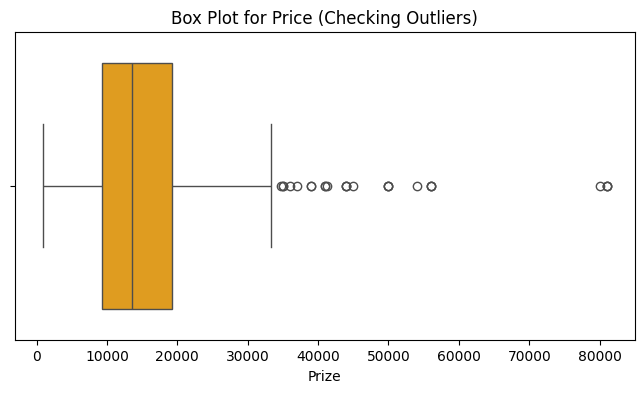

In [ ]:
# Box Plot to check outliers (e.g., for Price)
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Prize'], color='orange')
plt.title('Box Plot for Price (Checking Outliers)')
plt.show()


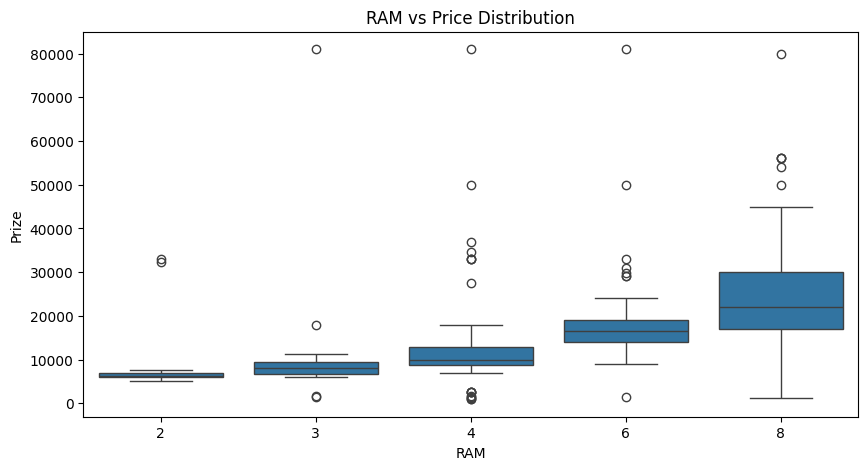

In [ ]:
# RAM vs Price distribution (Box plot with category)
if 'RAM' in df.columns and 'Prize' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x='RAM', y='Prize', data=df)
    plt.title('RAM vs Price Distribution')
    plt.show()

In [ ]:
# IQR Method(Detect and Remove Outliers)
Q1 = df['Prize'].quantile(0.25)
Q3 = df['Prize'].quantile(0.75)
IQR = Q3 - Q1

df = df[~((df['Prize'] < (Q1 - 1.5 * IQR)) | (df['Prize'] > (Q3 + 1.5 * IQR)))]

In [ ]:
# One Hot Encoding(Convert Categorical Variables into Numerical Format)
df = pd.get_dummies(df,columns=['Model','Colour','Rear Camera','Front Camera','Processor_'],drop_first=True)

In [ ]:
from sklearn.preprocessing import StandardScaler

# Text Cleaning (For categorical string columns)
categorical_string_cols = ['colour', 'brand']
for col in categorical_string_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.lower().str.strip()

In [ ]:
# Log Transformation for Target Variable (Price) to handle skewness
if 'price' in df.columns:
    df['price_log'] = np.log1p(df['Prize'])
    print("Log transformation applied to Prize.")

In [ ]:
# Feature Scaling for Numerical Features (Except target)
scaler = StandardScaler()
numerical_cols = df.select_dtypes(include=[np.number]).columns.drop(['Prize', 'Prize_log'], errors='ignore')

if len(numerical_cols) > 0:
    df[numerical_cols] = scaler.fit_transform(df[numerical_cols])
    print("Feature scaling applied to numerical columns.")

Feature scaling applied to numerical columns.


In [ ]:
# Feature Importance using Random Forest
x = df.drop('Prize', axis=1) if 'Prize' in df.columns else df
y = df['Prize'] if 'Prize' in df.columns else None

if y is not None:
# Random Forest Model
  rf_model = RandomForestRegressor(random_state=42)
  rf_model.fit(x,y)

In [ ]:
# Feature Importance scores
feature_importances = pd.Series(rf_model.feature_importances_, index=x.columns)
print("\n--- Top 10 Important Features for Prize Prediction ---")
display(feature_importances.nlargest(10))


--- Top 10 Important Features for Prize Prediction ---


,0
Memory,0.465479
Battery_,0.128680
Unnamed: 0,0.089699
Mobile Height,0.067974
RAM,0.061552
Front Camera_5MP,0.022476
Front Camera_16MP,0.012431
"Processor__Dimensity 1080, Octa Core",0.009522
Model_SAMSUNG Galaxy A34 5G,0.008992
Rear Camera_50MP,0.008875


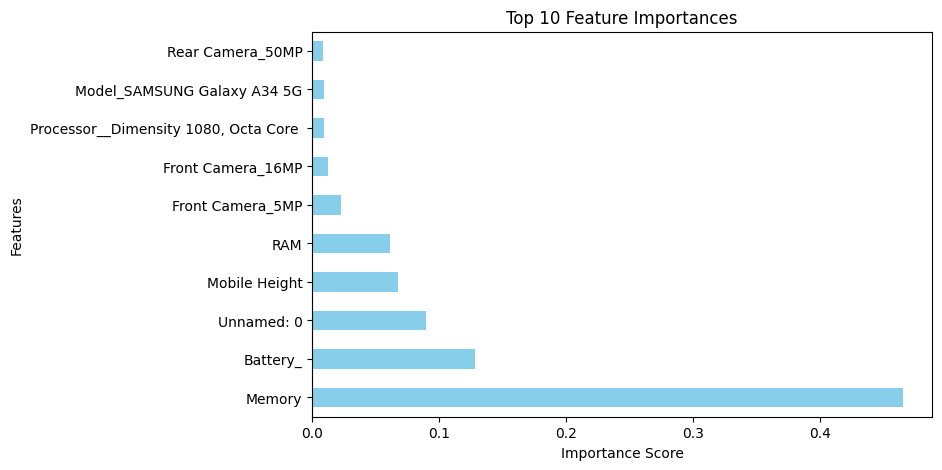

In [ ]:
# Top 10 features bar plot
plt.figure(figsize=(8, 5))
feature_importances.nlargest(10).plot(kind='barh', color='skyblue')
plt.title('Top 10 Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

if 'Prize' in df.columns:
    X = df.drop('Prize', axis=1)

    # data scale For PCA
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # PCA apply
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    print("=== PCA Dimensionality Reduction ===")
    print("Original shape:", X.shape)
    print("Reduced shape after PCA:", X_pca.shape)
    print("Explained Variance Ratio:", pca.explained_variance_ratio_)

=== PCA Dimensionality Reduction ===
Original shape: (516, 574)
Reduced shape after PCA: (516, 2)
Explained Variance Ratio: [0.01063625 0.00861548]


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 1200.0920192307692
Root Mean Squared Error (RMSE): 2074.8978592958683


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}


for name, model in models.items():
    # Model train
    model.fit(x_train,y_train)

    # Prediction
    y_pred = model.predict(x_test)

    # Metrics calculate
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Model: {name}")
    print(f" - MAE: {mae}")
    print(f" - R2 Score: {r2}\n")

Model: Linear Regression
 - MAE: 1321.3494145281927
 - R2 Score: 0.8996365984801866

Model: Decision Tree
 - MAE: 802.1346153846154
 - R2 Score: 0.860972673899645

Model: Random Forest
 - MAE: 1200.0920192307692
 - R2 Score: 0.9093118792775262



In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# Model initialize
rf = RandomForestRegressor(random_state=42)

# Parameters  list
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

# GridSearchCV setup (CV = 5-fold cross validation)
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# grid search
grid_search.fit(x_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Model:", grid_search.best_estimator_)

Best Parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Best Model: RandomForestRegressor(max_depth=20, n_estimators=200, random_state=42)


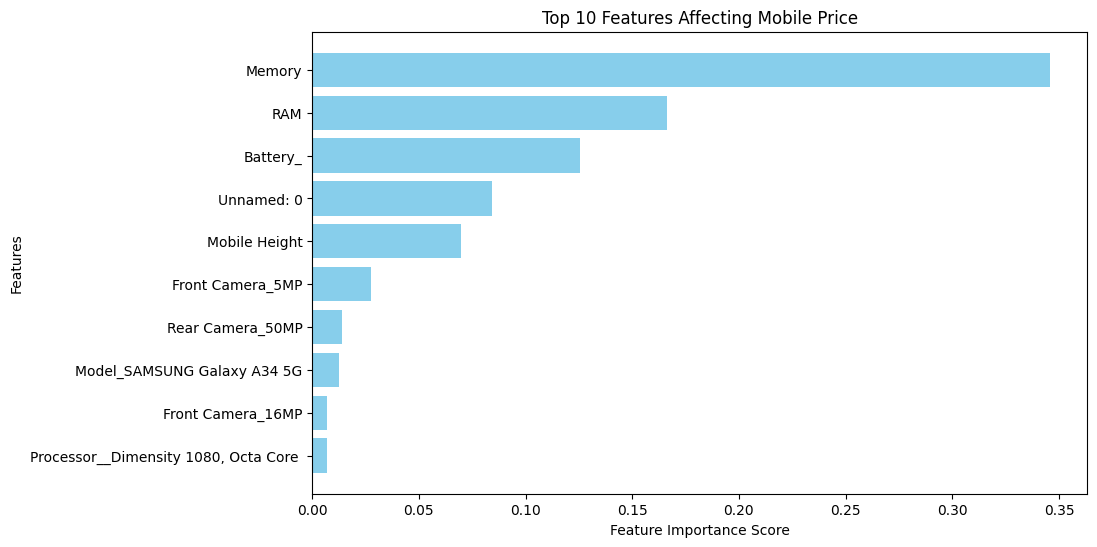

Top 10 Important Features:
                                   Feature  Importance
1                                   Memory    0.345914
2                                      RAM    0.166147
3                                 Battery_    0.125346
0                               Unnamed: 0    0.084385
5                            Mobile Height    0.069818
461                       Front Camera_5MP    0.027652
450                       Rear Camera_50MP    0.013987
107            Model_SAMSUNG Galaxy A34 5G    0.012362
455                      Front Camera_16MP    0.007015
466  Processor__Dimensity 1080, Octa Core     0.006827


In [ ]:
# Extract feature importances from the trained model[span_9](start_span)[span_9](end_span)
importances = model.feature_importances_
feature_names = x.columns

# Create a DataFrame and sort in descending order
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot Top 10 Features
plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'][:10], feature_imp_df['Importance'][:10], color='skyblue')
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Top 10 Features Affecting Mobile Price')
plt.gca().invert_yaxis()  # Display highest importance at the top
plt.show()

print("Top 10 Important Features:")
print(feature_imp_df.head(10))

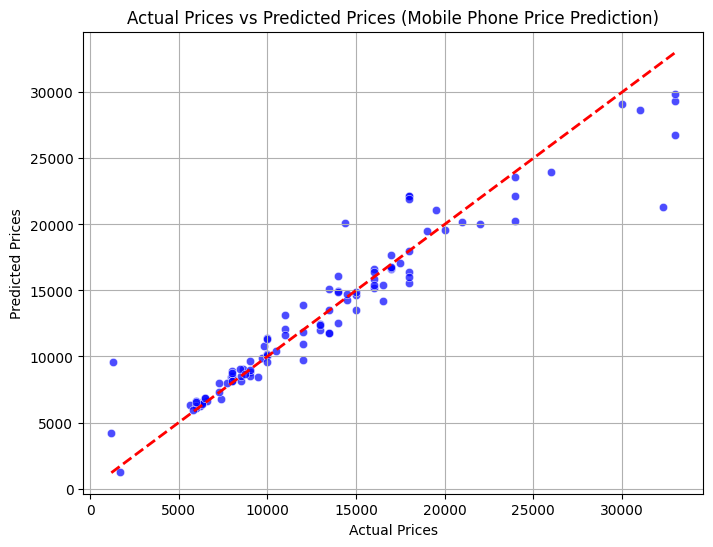

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual Prices vs Predicted Prices (Mobile Phone Price Prediction)')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.grid(True)
plt.show()